In [1]:

# =========================================================
# CELL 1: LOAD FINAL MODEL AND TEST DATA
# =========================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import joblib

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

import matplotlib.pyplot as plt

# 1. Đường dẫn dự án
PROJECT_DIR = Path(
    r"C:\CreditAI_Project_Starter\CreditAI_Project"
)

MODELS_DIR = PROJECT_DIR / "models"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"
METRICS_DIR = REPORTS_DIR / "metrics"
FIGURES_DIR = REPORTS_DIR / "figures"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 2. Đọc cấu hình mô hình
config_path = (
    MODELS_DIR / "credit_default_config.json"
)

with open(config_path, "r", encoding="utf-8") as f:
    model_config = json.load(f)

# 3. Tải mô hình
model_path = (
    MODELS_DIR / model_config["model_file"]
)

final_model = joblib.load(model_path)

# 4. Đọc tập Test
test_path = PROCESSED_DIR / "test_features.csv"

assert test_path.exists(), (
    f"Không tìm thấy tập Test: {test_path}"
)

test_df = pd.read_csv(test_path)

# 5. Tách đặc trưng và nhãn
feature_columns = model_config["feature_columns"]
target_col = "default payment next month"

assert target_col in test_df.columns, (
    f"Không tìm thấy cột nhãn: {target_col}"
)

missing_features = [
    col for col in feature_columns
    if col not in test_df.columns
]

assert not missing_features, (
    f"Thiếu đặc trưng: {missing_features}"
)

X_test = test_df[feature_columns].copy()
y_test = test_df[target_col].astype(int)

# 6. Kiểm tra dữ liệu
assert X_test.shape[1] == 28
assert len(X_test) == 4500
assert X_test.isna().sum().sum() == 0
assert np.isfinite(X_test.to_numpy()).all()
assert set(y_test.unique()).issubset({0, 1})

print("===== FINAL MODEL LOADED =====")
print("Model:", model_config["model_name"])
print("Threshold:", model_config["decision_threshold"])
print("Number of Features:", len(feature_columns))

print("\n===== TEST DATA CHECK =====")
print("Test Shape:", X_test.shape)
print("Test Labels:", y_test.shape)
print("Missing Values:", X_test.isna().sum().sum())
print("Default Rate:", round(y_test.mean() * 100, 2), "%")

print("\n===== TEST LABEL DISTRIBUTION =====")
print(y_test.value_counts().sort_index())

print("\nCELL 1 HOÀN THÀNH!")


===== FINAL MODEL LOADED =====
Model: Hist Gradient Boosting Tuned
Threshold: 0.25
Number of Features: 28

===== TEST DATA CHECK =====
Test Shape: (4500, 28)
Test Labels: (4500,)
Missing Values: 0
Default Rate: 22.13 %

===== TEST LABEL DISTRIBUTION =====
default payment next month
0    3504
1     996
Name: count, dtype: int64

CELL 1 HOÀN THÀNH!


In [2]:

# =========================================================
# CELL 2: FINAL MODEL EVALUATION ON TEST DATA
# =========================================================

# 1. Lấy ngưỡng đã chốt từ Validation
final_threshold = float(
    model_config["decision_threshold"]
)

# 2. Dự đoán xác suất default trên Test
test_proba = final_model.predict_proba(
    X_test
)[:, 1]

# 3. Chuyển xác suất thành nhãn dự đoán
test_pred = (
    test_proba >= final_threshold
).astype(int)

# 4. Tính các chỉ số đánh giá
test_metrics = {
    "Model": model_config["model_name"],
    "Threshold": final_threshold,
    "ROC_AUC": roc_auc_score(
        y_test, test_proba
    ),
    "PR_AUC": average_precision_score(
        y_test, test_proba
    ),
    "Accuracy": accuracy_score(
        y_test, test_pred
    ),
    "Precision": precision_score(
        y_test, test_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_pred,
        zero_division=0
    ),
    "F1": f1_score(
        y_test, test_pred,
        zero_division=0
    )
}

test_metrics_df = pd.DataFrame([test_metrics])

print("===== FINAL TEST METRICS =====")
display(test_metrics_df.round(4))

# 5. Confusion Matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

test_cm_df = pd.DataFrame(
    [
        [tn, fp],
        [fn, tp]
    ],
    index=["Actual 0", "Actual 1"],
    columns=["Predicted 0", "Predicted 1"]
)

print("\n===== TEST CONFUSION MATRIX =====")
display(test_cm_df)

# 6. Classification Report
print("\n===== TEST CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_test,
        test_pred,
        target_names=["No Default", "Default"],
        zero_division=0
    )
)

# 7. Diễn giải số lượng khách hàng
print("\n===== BUSINESS INTERPRETATION =====")
print("Total Customers:", len(y_test))
print("Actual Default:", int(y_test.sum()))
print("True Positive:", tp)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Negative:", tn)

print(
    "Detected Default Rate:",
    round(tp / (tp + fn) * 100, 2),
    "%"
)

print(
    "Missed Default Rate:",
    round(fn / (tp + fn) * 100, 2),
    "%"
)

# 8. Lưu kết quả
test_metrics_df.to_csv(
    METRICS_DIR / "37_final_test_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

test_cm_df.to_csv(
    METRICS_DIR / "38_final_test_confusion_matrix.csv",
    encoding="utf-8-sig"
)

print("\nĐã lưu kết quả đánh giá Test.")
print("CELL 2 HOÀN THÀNH!")


===== FINAL TEST METRICS =====


,Model,Threshold,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1
0,Hist Gradient Boosting Tuned,0.25,0.7804,0.5536,0.7711,0.4864,0.6094,0.541



===== TEST CONFUSION MATRIX =====


,Predicted 0,Predicted 1
Actual 0,2863,641
Actual 1,389,607



===== TEST CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

  No Default       0.88      0.82      0.85      3504
     Default       0.49      0.61      0.54       996

    accuracy                           0.77      4500
   macro avg       0.68      0.71      0.69      4500
weighted avg       0.79      0.77      0.78      4500


===== BUSINESS INTERPRETATION =====
Total Customers: 4500
Actual Default: 996
True Positive: 607
False Positive: 641
False Negative: 389
True Negative: 2863
Detected Default Rate: 60.94 %
Missed Default Rate: 39.06 %

Đã lưu kết quả đánh giá Test.
CELL 2 HOÀN THÀNH!


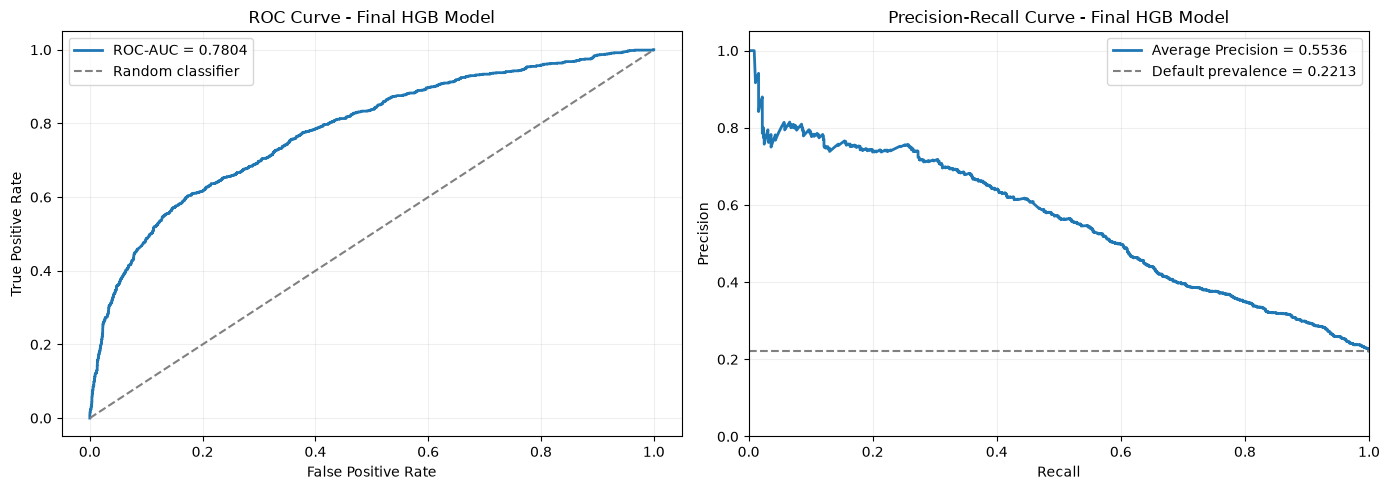

===== FINAL CURVE METRICS =====
ROC-AUC: 0.7804
Average Precision: 0.5536
Default Prevalence: 0.2213

Đã lưu biểu đồ: C:\CreditAI_Project_Starter\CreditAI_Project\reports\figures\15_final_roc_pr_curves.png
CELL 3 HOÀN THÀNH!


In [3]:

# =========================================================
# CELL 3: ROC CURVE AND PRECISION-RECALL CURVE
# =========================================================

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# 1. Tính dữ liệu ROC Curve
fpr, tpr, roc_thresholds = roc_curve(
    y_test, test_proba
)

roc_auc = roc_auc_score(
    y_test, test_proba
)

# 2. Tính dữ liệu Precision-Recall Curve
precision_values, recall_values, pr_thresholds = (
    precision_recall_curve(y_test, test_proba)
)

average_precision = average_precision_score(
    y_test, test_proba
)

# 3. Tỷ lệ default thực tế
default_rate = y_test.mean()

# 4. Vẽ biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
axes[0].plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random classifier"
)

axes[0].set_title("ROC Curve - Final HGB Model")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Precision-Recall Curve
axes[1].plot(
    recall_values,
    precision_values,
    linewidth=2,
    label=f"Average Precision = {average_precision:.4f}"
)

axes[1].axhline(
    default_rate,
    linestyle="--",
    color="gray",
    label=f"Default prevalence = {default_rate:.4f}"
)

axes[1].set_title(
    "Precision-Recall Curve - Final HGB Model"
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()

# 5. Lưu hình
figure_path = (
    FIGURES_DIR / "15_final_roc_pr_curves.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Lưu dữ liệu đường cong
roc_df = pd.DataFrame({
    "FPR": fpr,
    "TPR": tpr,
    "Threshold": roc_thresholds
})

pr_df = pd.DataFrame({
    "Precision": precision_values,
    "Recall": recall_values
})

roc_df.to_csv(
    METRICS_DIR / "39_final_roc_curve.csv",
    index=False,
    encoding="utf-8-sig"
)

pr_df.to_csv(
    METRICS_DIR / "40_final_pr_curve.csv",
    index=False,
    encoding="utf-8-sig"
)

print("===== FINAL CURVE METRICS =====")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Average Precision: {average_precision:.4f}")
print(f"Default Prevalence: {default_rate:.4f}")

print("\nĐã lưu biểu đồ:", figure_path)
print("CELL 3 HOÀN THÀNH!")


===== PROBABILITY CALIBRATION METRICS =====
Brier Score: 0.1349
Log Loss: 0.4296

===== CALIBRATION BY RISK DECILE =====


,Risk_Decile,So_khach_hang,So_default,Xac_suat_du_doan_TB,Ty_le_default_thuc_te,Sai_lech
0,1,450,25,0.0507,0.0556,0.0048
1,2,450,32,0.0713,0.0711,-0.0001
2,3,450,30,0.0911,0.0667,-0.0244
3,4,450,50,0.1120,0.1111,-0.0009
4,5,450,66,0.1352,0.1467,0.0114
5,6,450,90,0.1613,0.2000,0.0387
6,7,450,78,0.2025,0.1733,-0.0292
7,8,450,118,0.2730,0.2622,-0.0108
8,9,450,193,0.4142,0.4289,0.0147
9,10,450,314,0.6978,0.6978,-0.0000


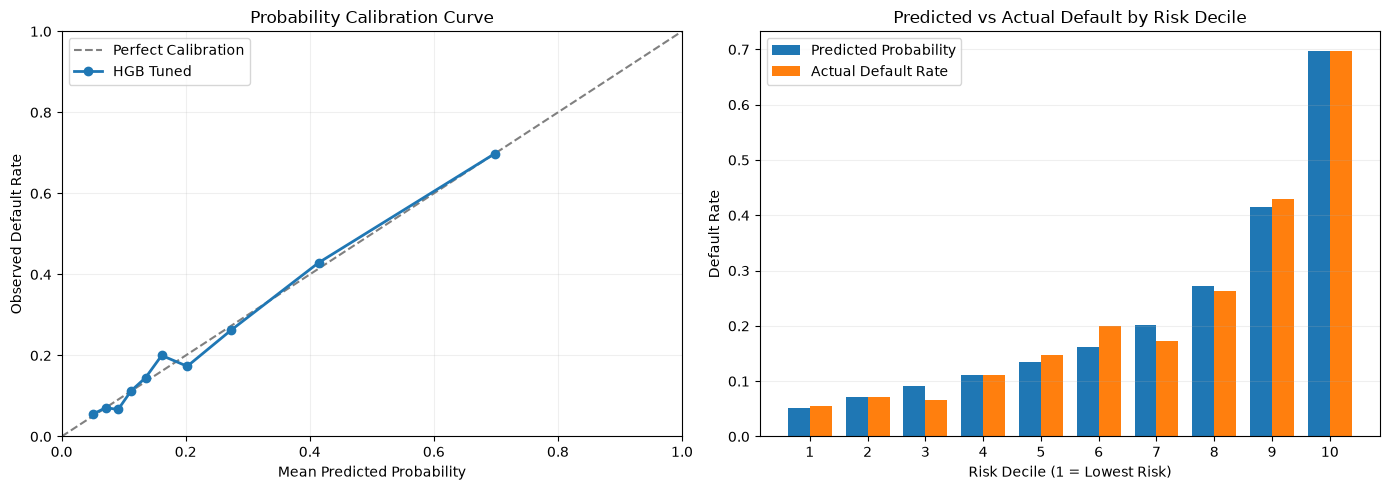


Đã lưu biểu đồ: C:\CreditAI_Project_Starter\CreditAI_Project\reports\figures\16_probability_calibration.png
CELL 4 HOÀN THÀNH!


In [4]:

# =========================================================
# CELL 4: PROBABILITY CALIBRATION EVALUATION
# =========================================================

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

# 1. Kiểm tra xác suất dự đoán
assert np.isfinite(test_proba).all()
assert ((test_proba >= 0) & (test_proba <= 1)).all()

# 2. Các chỉ số đánh giá xác suất
brier_score = brier_score_loss(y_test, test_proba)
logloss_score = log_loss(y_test, test_proba)

print("===== PROBABILITY CALIBRATION METRICS =====")
print(f"Brier Score: {brier_score:.4f}")
print(f"Log Loss: {logloss_score:.4f}")

# 3. Chia xác suất thành 10 nhóm theo phân vị
calibration_df = pd.DataFrame({
    "Actual_Default": y_test.to_numpy(),
    "Predicted_Probability": test_proba
})

calibration_df["Risk_Decile"] = pd.qcut(
    calibration_df["Predicted_Probability"].rank(
        method="first"
    ),
    q=10,
    labels=False
) + 1

# 4. Tổng hợp kết quả từng nhóm
calibration_summary = (
    calibration_df.groupby("Risk_Decile")
    .agg(
        So_khach_hang=("Actual_Default", "size"),
        So_default=("Actual_Default", "sum"),
        Xac_suat_du_doan_TB=(
            "Predicted_Probability", "mean"
        ),
        Ty_le_default_thuc_te=(
            "Actual_Default", "mean"
        )
    )
    .reset_index()
)

calibration_summary["Sai_lech"] = (
    calibration_summary["Ty_le_default_thuc_te"]
    - calibration_summary["Xac_suat_du_doan_TB"]
)

print("\n===== CALIBRATION BY RISK DECILE =====")
display(calibration_summary.round(4))

# 5. Tính điểm cho Calibration Curve
fraction_positive, mean_predicted = calibration_curve(
    y_test,
    test_proba,
    n_bins=10,
    strategy="quantile"
)

# 6. Vẽ biểu đồ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

axes[0].plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    linewidth=2,
    label="HGB Tuned"
)

axes[0].set_title("Probability Calibration Curve")
axes[0].set_xlabel("Mean Predicted Probability")
axes[0].set_ylabel("Observed Default Rate")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[0].grid(alpha=0.2)

# Biểu đồ so sánh xác suất và tỷ lệ thực tế
x = np.arange(len(calibration_summary))
width = 0.38

axes[1].bar(
    x - width / 2,
    calibration_summary["Xac_suat_du_doan_TB"],
    width,
    label="Predicted Probability"
)

axes[1].bar(
    x + width / 2,
    calibration_summary["Ty_le_default_thuc_te"],
    width,
    label="Actual Default Rate"
)

axes[1].set_xticks(x)
axes[1].set_xticklabels(
    calibration_summary["Risk_Decile"]
)
axes[1].set_title("Predicted vs Actual Default by Risk Decile")
axes[1].set_xlabel("Risk Decile (1 = Lowest Risk)")
axes[1].set_ylabel("Default Rate")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.2)

plt.tight_layout()

figure_path = FIGURES_DIR / "16_probability_calibration.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Lưu kết quả
calibration_summary.to_csv(
    METRICS_DIR / "41_calibration_by_decile.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame([{
    "Model": model_config["model_name"],
    "Brier_Score": brier_score,
    "Log_Loss": logloss_score
}]).to_csv(
    METRICS_DIR / "42_calibration_metrics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nĐã lưu biểu đồ:", figure_path)
print("CELL 4 HOÀN THÀNH!")
